# 01 - Dataset exploration (v2)
Galaxy10 DECaLS | Phase 1 | read-only exploration

**Rules for this notebook**
- No train/validation/test split is created here. The split comes from the protocol.
- Statistics computed on the full dataset are *descriptive only*. Normalization statistics for training must come from the training split alone.
- Every number shown is computed from the data. Only the published reference values from the astroNN docs (class counts, SHA256) are hardcoded.
- Requires: numpy, h5py, matplotlib, pandas, scipy.

In [15]:
import hashlib
import time
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import ndimage
from scipy.spatial import cKDTree

SEED = 42

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Galaxy10_DECals.h5"
PROCESSED = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "results" / "figures" / "exploration"
assert DATA_PATH.exists(), "Dataset not found: run this notebook from galaxy10-research/notebooks/"
PROCESSED.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 80


def savefig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=110, bbox_inches="tight")


# Reference values published in the astroNN Galaxy10 DECaLS documentation
EXPECTED_SHA256 = "19AEFC477C41BB7F77FF07599A6B82A038DC042F889A111B0D4D98BB755C1571"
EXPECTED_COUNTS = [1081, 1853, 2645, 2027, 334, 2043, 1829, 2628, 1423, 1873]
CLASS_NAMES = [
    "Disturbed",
    "Merging",
    "Round Smooth",
    "In-between Round Smooth",
    "Cigar Shaped Smooth",
    "Barred Spiral",
    "Unbarred Tight Spiral",
    "Unbarred Loose Spiral",
    "Edge-on without Bulge",
    "Edge-on with Bulge",
]
assert len(CLASS_NAMES) == len(EXPECTED_COUNTS) == 10
print("Setup OK")

Setup OK


## 1. File integrity
Compare the SHA256 of the downloaded file with the value published in the docs. A corrupted download can fail silently later.

In [16]:
def sha256_file(path, chunk=8 * 1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        while block := fh.read(chunk):
            h.update(block)
    return h.hexdigest()


t0 = time.time()
got = sha256_file(DATA_PATH)
match = got.lower() == EXPECTED_SHA256.lower()
print(f"SHA256 match: {match}  ({time.time() - t0:.0f}s)")
print(f"File size: {DATA_PATH.stat().st_size / 1e9:.2f} GB")
assert match, "Checksum mismatch: re-download the file"

SHA256 match: True  (3s)
File size: 2.74 GB


## 2. HDF5 structure and memory budget
`f["images"]` is a handle to data on disk, not an array in RAM. Slicing it reads only the requested part.

In [17]:
with h5py.File(DATA_PATH, "r") as f:
    print("File attributes:", dict(f.attrs))
    for key in f.keys():
        d = f[key]
        print(f"{key:9s} shape={d.shape!s:22s} dtype={d.dtype!s:8s} "
              f"compression={d.compression} opts={d.compression_opts} chunks={d.chunks}")
    N, H, W, C = f["images"].shape

print(f"\nN={N}, image shape=({H}, {W}, {C})")
print(f"On disk: {DATA_PATH.stat().st_size / 1e9:.2f} GB")
print("\nIn-memory size of the FULL image array:")
for tag, h, w, itemsize in [("256x256 uint8", H, W, 1), ("256x256 float32", H, W, 4),
                            ("128x128 uint8", 128, 128, 1), ("128x128 float32", 128, 128, 4)]:
    print(f"  {tag:16s} {N * h * w * C * itemsize / 1e9:6.2f} GB")

File attributes: {}
ans       shape=(17736,)               dtype=uint8    compression=gzip opts=4 chunks=(8868,)
dec       shape=(17736,)               dtype=float64  compression=None opts=None chunks=None
images    shape=(17736, 256, 256, 3)   dtype=uint8    compression=gzip opts=4 chunks=(555, 16, 16, 1)
pxscale   shape=(17736,)               dtype=float64  compression=None opts=None chunks=None
ra        shape=(17736,)               dtype=float64  compression=None opts=None chunks=None
redshift  shape=(17736,)               dtype=float64  compression=None opts=None chunks=None

N=17736, image shape=(256, 256, 3)
On disk: 2.74 GB

In-memory size of the FULL image array:
  256x256 uint8      3.49 GB
  256x256 float32   13.95 GB
  128x128 uint8      0.87 GB
  128x128 float32    3.49 GB


**Decision for the pipeline:** keep images as `uint8` in memory, convert to float32 per batch, and cache a 128x128 `uint8` copy in `data/processed/` (generated by a script). Casting the whole array to float32, as the docs snippet does, does not fit on a typical laptop.

In [18]:
with h5py.File(DATA_PATH, "r") as f:
    labels = f["ans"][:].astype(np.int64)
    ra, dec = f["ra"][:], f["dec"][:]
    redshift, pxscale = f["redshift"][:], f["pxscale"][:]


def load_images(idx):
    """Read images by index (unique indices, any order). Returns uint8 array (len(idx), H, W, 3)."""
    idx = np.asarray(idx)
    order = np.argsort(idx)
    with h5py.File(DATA_PATH, "r") as f:
        block = f["images"][idx[order]]  # h5py needs increasing, unique indices
    out = np.empty_like(block)
    out[order] = block
    return out


print("Metadata arrays loaded:", labels.shape, ra.shape, dec.shape, redshift.shape, pxscale.shape)

Metadata arrays loaded: (17736,) (17736,) (17736,) (17736,) (17736,)


## 3. Class distribution

 class                    name  count  percent  ratio_to_largest
     0               Disturbed   1081     6.09             0.409
     1                 Merging   1853    10.45             0.701
     2            Round Smooth   2645    14.91             1.000
     3 In-between Round Smooth   2027    11.43             0.766
     4     Cigar Shaped Smooth    334     1.88             0.126
     5           Barred Spiral   2043    11.52             0.772
     6   Unbarred Tight Spiral   1829    10.31             0.691
     7   Unbarred Loose Spiral   2628    14.82             0.994
     8   Edge-on without Bulge   1423     8.02             0.538
     9      Edge-on with Bulge   1873    10.56             0.708

Imbalance (largest / smallest class): 7.9:1


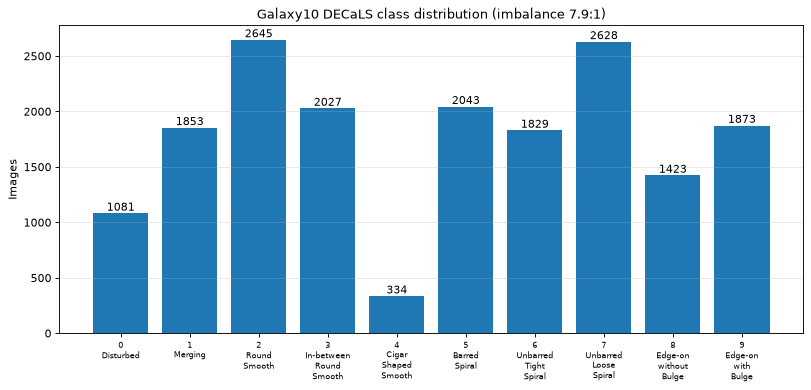

In [19]:
counts = np.bincount(labels, minlength=10)
assert counts.tolist() == EXPECTED_COUNTS, f"Counts differ from the docs: {counts.tolist()}"

dist = pd.DataFrame({"class": range(10), "name": CLASS_NAMES, "count": counts})
dist["percent"] = (100 * dist["count"] / dist["count"].sum()).round(2)
dist["ratio_to_largest"] = (dist["count"] / dist["count"].max()).round(3)
print(dist.to_string(index=False))
imbalance = counts.max() / counts.min()
print(f"\nImbalance (largest / smallest class): {imbalance:.1f}:1")

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(range(10), counts)
ax.set_xticks(range(10))
ax.set_xticklabels([f"{i}\n" + n.replace(" ", "\n") for i, n in enumerate(CLASS_NAMES)], fontsize=7)
ax.bar_label(bars)
ax.set_ylabel("Images")
ax.set_title(f"Galaxy10 DECaLS class distribution (imbalance {imbalance:.1f}:1)")
ax.grid(axis="y", alpha=0.3)
savefig(fig, "class_distribution.png")
plt.show()

## 4. Random samples (seeded)
Five random images per class (not the first index of each class).

KeyboardInterrupt: 

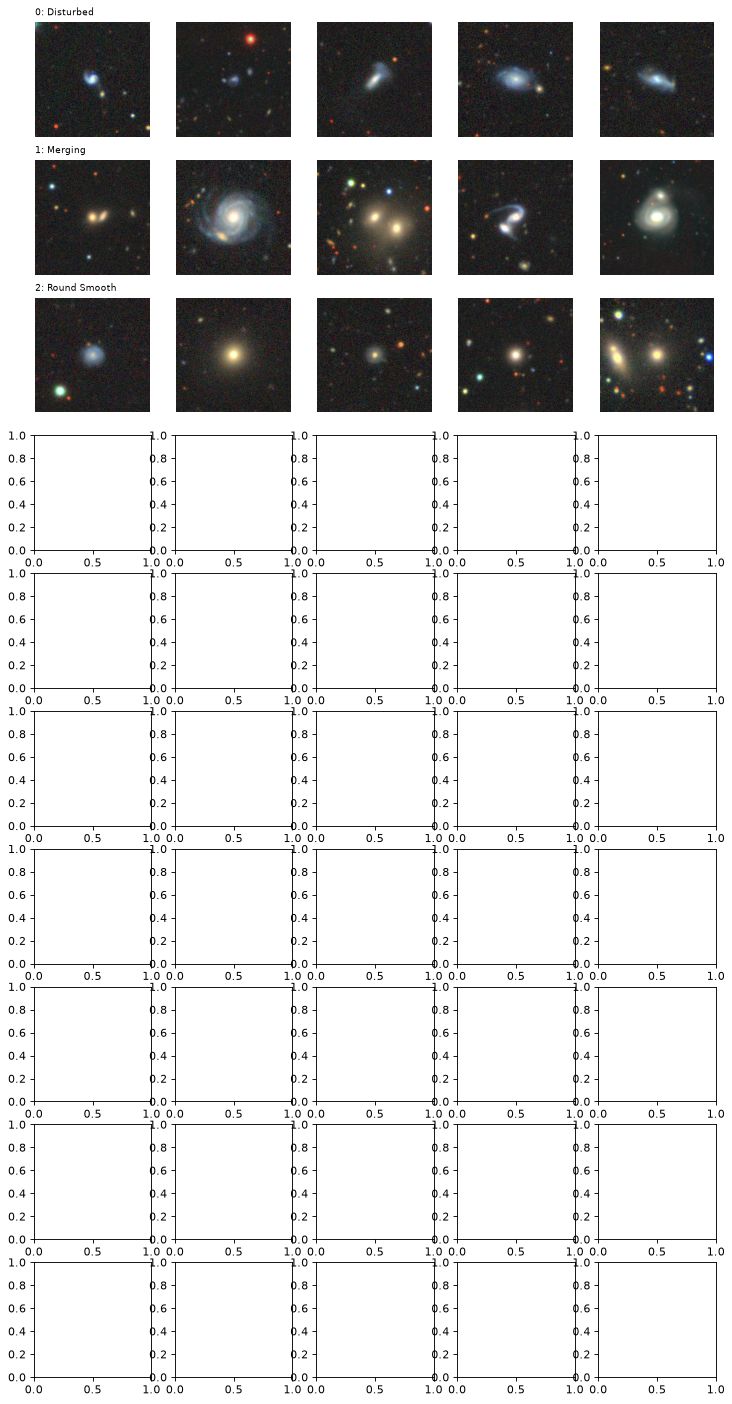

In [20]:
N_PER_CLASS = 5
rng_s = np.random.default_rng(SEED)
fig, axes = plt.subplots(10, N_PER_CLASS, figsize=(2.2 * N_PER_CLASS, 2.2 * 10))
for c in range(10):
    idx = np.sort(rng_s.choice(np.where(labels == c)[0], N_PER_CLASS, replace=False))
    imgs = load_images(idx)
    for j, ax in enumerate(axes[c]):
        ax.imshow(imgs[j])
        ax.axis("off")
        if j == 0:
            ax.set_title(f"{c}: {CLASS_NAMES[c]}", fontsize=8, loc="left")
fig.tight_layout()
savefig(fig, "samples_per_class.png")
plt.show()

## 5. Metadata: ra, dec, redshift, pxscale

In [ ]:
meta = pd.DataFrame({"label": labels, "ra": ra, "dec": dec, "redshift": redshift, "pxscale": pxscale})
print("NaN counts:")
print(meta.isna().sum().to_string())
print("\ninf counts:")
print(np.isinf(meta[["ra", "dec", "redshift", "pxscale"]]).sum().to_string())
print("\nredshift <= 0:", int((meta["redshift"] <= 0).sum()))
print("distinct pxscale values (rounded to 4 d.p.):", len(np.unique(np.round(pxscale[np.isfinite(pxscale)], 4))))
print()
print(meta.groupby("label")[["redshift", "pxscale"]].agg(["min", "median", "max"]).round(4).to_string())

NaN counts:
label        0
ra           0
dec          0
redshift    92
pxscale      0

inf counts:
ra          0
dec         0
redshift    0
pxscale     0

redshift <= 0: 3
distinct pxscale values (rounded to 4 d.p.): 2

      redshift                 pxscale              
           min  median     max     min median    max
label                                               
0       0.0050  0.0647  0.2376   0.262  0.262  0.524
1       0.0024  0.0907  1.3742   0.262  0.262  0.524
2       0.0020  0.0927  1.4391   0.262  0.262  0.524
3       0.0000  0.0796  1.1554   0.262  0.262  0.524
4       0.0042  0.0639  0.1650   0.262  0.262  0.524
5      -0.0001  0.0664  0.9409   0.262  0.262  0.524
6       0.0000  0.0625  0.2078   0.262  0.262  0.524
7       0.0000  0.0748  1.4416   0.262  0.262  0.524
8       0.0024  0.0353  0.7348   0.262  0.262  0.524
9       0.0062  0.0749  0.1498   0.262  0.262  0.524


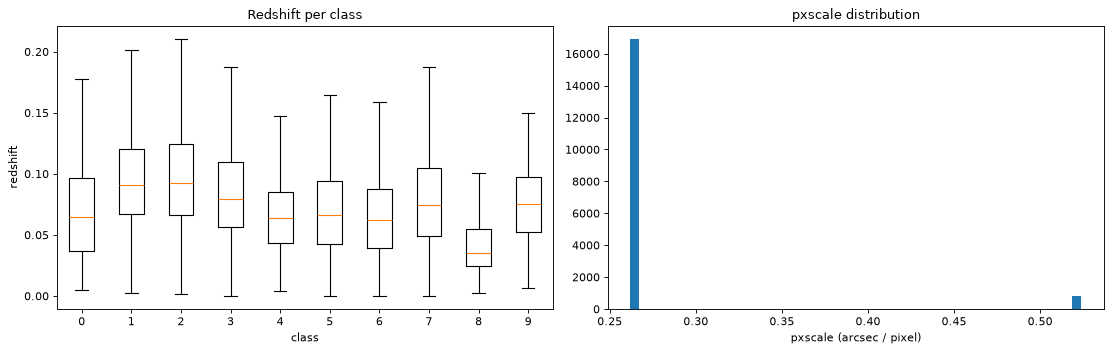

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].boxplot([meta.loc[meta.label == c, "redshift"].dropna() for c in range(10)], showfliers=False)
axes[0].set_xticklabels([str(c) for c in range(10)])
axes[0].set_xlabel("class")
axes[0].set_ylabel("redshift")
axes[0].set_title("Redshift per class")
axes[1].hist(pxscale[np.isfinite(pxscale)], bins=50)
axes[1].set_xlabel("pxscale (arcsec / pixel)")
axes[1].set_title("pxscale distribution")
fig.tight_layout()
savefig(fig, "metadata.png")
plt.show()

## 6. Leakage check: images at (almost) the same sky position
If the same galaxy appears twice, it can end up in both train and test. Close pairs can also be genuine companions (for example merging systems), so **inspect them visually** before deciding anything.

In [ ]:
TOL_ARCSEC = 3.0

ok = np.isfinite(ra) & np.isfinite(dec)
idx_ok = np.where(ok)[0]
ra_r, dec_r = np.deg2rad(ra[ok]), np.deg2rad(dec[ok])
xyz = np.c_[np.cos(dec_r) * np.cos(ra_r), np.cos(dec_r) * np.sin(ra_r), np.sin(dec_r)]
tree = cKDTree(xyz)
pairs_local = np.array(sorted(tree.query_pairs(np.deg2rad(TOL_ARCSEC / 3600))), dtype=int).reshape(-1, 2)
pairs = idx_ok[pairs_local]
chord = np.linalg.norm(xyz[pairs_local[:, 0]] - xyz[pairs_local[:, 1]], axis=1)
sep_arcsec = np.rad2deg(2 * np.arcsin(chord / 2)) * 3600

print(f"Pairs closer than {TOL_ARCSEC} arcsec: {len(pairs)}")
if len(pairs):
    same = labels[pairs[:, 0]] == labels[pairs[:, 1]]
    print("  same label:", int(same.sum()), "| different label:", int((~same).sum()))
    print("  distinct images involved:", len(np.unique(pairs)))

Pairs closer than 3.0 arcsec: 65
  same label: 5 | different label: 60
  distinct images involved: 130


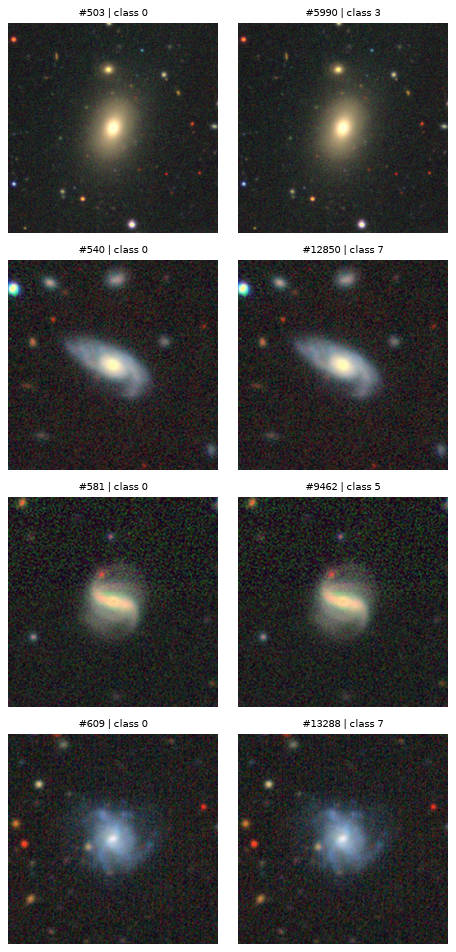

In [ ]:
if len(pairs):
    show = pairs[np.argsort(sep_arcsec)[:4]]
    fig, axes = plt.subplots(len(show), 2, figsize=(6, 3 * len(show)), squeeze=False)
    for r, (i, j) in enumerate(show):
        imgs = load_images([i, j])
        for k, gi in enumerate((i, j)):
            axes[r][k].imshow(imgs[k])
            axes[r][k].axis("off")
            axes[r][k].set_title(f"#{gi} | class {labels[gi]}", fontsize=9)
    fig.tight_layout()
    savefig(fig, "closest_pairs.png")
    plt.show()
else:
    print("No close pairs to display.")

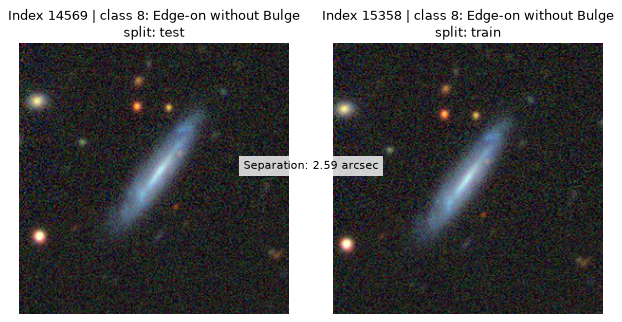

In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

pairs_to_inspect = [(8043, 9089)]

# Map each sample index to its split.
split_by_index = {}
for split_name in ("train", "val", "test"):
    split_indices = np.load(
        PROJECT_ROOT / "splits" / f"{split_name}_idx.npy"
    )
    for index in split_indices:
        split_by_index[int(index)] = split_name

fig, axes = plt.subplots(
    len(pairs_to_inspect), 2,
    figsize=(8, 4 * len(pairs_to_inspect)),
    squeeze=False,
)

for row, (i, j) in enumerate(pairs_to_inspect):
    # Angular separation, using the haversine formula.
    ra1, ra2 = np.deg2rad(ra[i]), np.deg2rad(ra[j])
    dec1, dec2 = np.deg2rad(dec[i]), np.deg2rad(dec[j])
    a = (
        np.sin((dec2 - dec1) / 2) ** 2
        + np.cos(dec1) * np.cos(dec2) * np.sin((ra2 - ra1) / 2) ** 2
    )
    separation_arcsec = 2 * np.arcsin(np.sqrt(a)) * 206264.806

    images = load_images([i, j])

    for col, index in enumerate((i, j)):
        axes[row, col].imshow(images[col])
        axes[row, col].set_title(
            f"Index {index} | class {labels[index]}: "
            f"{CLASS_NAMES[labels[index]]}\n"
            f"split: {split_by_index[index]}"
        )
        axes[row, col].axis("off")

    fig.text(
        0.5,
        1 - (row + 0.5) / len(pairs_to_inspect),
        f"Separation: {separation_arcsec:.2f} arcsec",
        ha="center",
        va="center",
        fontsize=10,
        bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"},
    )

plt.tight_layout()
plt.show()

## 7. Per-image statistics pass
One pass over all images computes: a content hash (exact duplicates), per-channel pixel stats, saturation and zero fractions, the **background level and noise** (from a 16-pixel border frame), and a **rough object size** (the connected bright region at the image center, after Gaussian smoothing). The object size is a crude proxy for the crop-vs-resize decision, not a measurement. Border pixels can contain stars, hence the median/MAD estimators.

The first run takes a few minutes (it reads and decompresses all images). The result is cached in `data/processed/`.

In [ ]:
STATS_PATH = PROCESSED / "image_stats_v2.npz"
FORCE_RECOMPUTE = False

BORDER_W = 16
_border = np.zeros((H, W), dtype=bool)
_border[:BORDER_W, :] = True
_border[-BORDER_W:, :] = True
_border[:, :BORDER_W] = True
_border[:, -BORDER_W:] = True
CENTER = (slice(H // 2 - 16, H // 2 + 16), slice(W // 2 - 16, W // 2 + 16))


def image_stats(img):
    g = img.astype(np.float32).mean(axis=2)
    b = g[_border]
    sky = float(np.median(b))
    noise = float(1.4826 * np.median(np.abs(b - sky)))
    gs = ndimage.gaussian_filter(g, 2.0)
    bs = gs[_border]
    sky_s = np.median(bs)
    sig_s = max(1.4826 * np.median(np.abs(bs - sky_s)), 0.5)
    lab, _ = ndimage.label(gs > sky_s + 3 * sig_s)
    ids = lab[CENTER][lab[CENTER] > 0]
    if ids.size == 0:
        diam = 0.0
    else:
        area = np.count_nonzero(lab == np.bincount(ids).argmax())
        diam = float(2 * np.sqrt(area / np.pi))
    return sky, noise, diam


def compute_stats(chunk=256):
    st = {
        "digests": np.empty(N, dtype="U32"),
        "px_min": np.empty((N, 3), np.uint8),
        "px_max": np.empty((N, 3), np.uint8),
        "ch_mean": np.empty((N, 3), np.float32),
        "ch_std": np.empty((N, 3), np.float32),
        "sat_frac": np.empty(N, np.float32),
        "zero_frac": np.empty(N, np.float32),
        "sky": np.empty(N, np.float32),
        "noise": np.empty(N, np.float32),
        "diam": np.empty(N, np.float32),
        "n": np.array(N),
    }
    t0 = time.time()
    with h5py.File(DATA_PATH, "r") as f:
        dset = f["images"]
        for s in range(0, N, chunk):
            block = dset[s:s + chunk]
            for k in range(len(block)):
                img, i = block[k], s + k
                flat = img.reshape(-1, 3)
                st["digests"][i] = hashlib.blake2b(img.tobytes(), digest_size=16).hexdigest()
                st["px_min"][i] = flat.min(axis=0)
                st["px_max"][i] = flat.max(axis=0)
                st["ch_mean"][i] = flat.mean(axis=0)
                st["ch_std"][i] = flat.std(axis=0)
                st["sat_frac"][i] = np.mean(img == 255)
                st["zero_frac"][i] = np.mean(np.all(img == 0, axis=2))
                st["sky"][i], st["noise"][i], st["diam"][i] = image_stats(img)
            print(f"  {min(s + chunk, N)}/{N} images ({time.time() - t0:.0f}s)")
    return st


if STATS_PATH.exists() and not FORCE_RECOMPUTE:
    st = dict(np.load(STATS_PATH))
    assert int(st["n"]) == N, "Cached stats do not match this dataset: set FORCE_RECOMPUTE = True"
    print("Loaded cached stats")
else:
    st = compute_stats()
    np.savez_compressed(STATS_PATH, **st)
    print("Stats computed and cached")

  256/17736 images (3s)
  512/17736 images (7s)
  768/17736 images (10s)
  1024/17736 images (14s)
  1280/17736 images (18s)
  1536/17736 images (21s)
  1792/17736 images (25s)
  2048/17736 images (28s)
  2304/17736 images (32s)
  2560/17736 images (35s)
  2816/17736 images (39s)
  3072/17736 images (42s)
  3328/17736 images (46s)
  3584/17736 images (50s)
  3840/17736 images (53s)
  4096/17736 images (59s)
  4352/17736 images (62s)
  4608/17736 images (66s)
  4864/17736 images (69s)
  5120/17736 images (73s)
  5376/17736 images (76s)
  5632/17736 images (80s)
  5888/17736 images (83s)
  6144/17736 images (87s)
  6400/17736 images (90s)
  6656/17736 images (93s)
  6912/17736 images (97s)
  7168/17736 images (101s)
  7424/17736 images (106s)
  7680/17736 images (110s)
  7936/17736 images (115s)
  8192/17736 images (119s)
  8448/17736 images (124s)
  8704/17736 images (128s)
  8960/17736 images (133s)
  9216/17736 images (137s)
  9472/17736 images (142s)
  9728/17736 images (146s)
  9984

### 7a. Exact duplicate images (identical pixels)

In [ ]:
dig = pd.Series(st["digests"])
vc = dig.value_counts()
dup_hashes = vc[vc > 1].index
print("Exact duplicate groups:", len(dup_hashes), "| images involved:", int(vc[vc > 1].sum()))
for h in dup_hashes[:10]:
    members = np.where(st["digests"] == h)[0]
    print("  indices", members.tolist(), "| labels", labels[members].tolist())

Exact duplicate groups: 60 | images involved: 121
  indices [11492, 12659, 15422] | labels [6, 7, 8]
  indices [503, 5990] | labels [0, 3]
  indices [540, 12850] | labels [0, 7]
  indices [581, 9462] | labels [0, 5]
  indices [609, 13288] | labels [0, 7]
  indices [622, 13357] | labels [0, 7]
  indices [625, 13363] | labels [0, 7]
  indices [678, 5220] | labels [0, 2]
  indices [683, 6739] | labels [0, 3]
  indices [686, 13624] | labels [0, 7]


### 7b. Pixel-level quality control

In [ ]:
print("Global pixel range per channel, min:", st["px_min"].min(axis=0).tolist(), " max:", st["px_max"].max(axis=0).tolist())
print("Mean per channel over images (descriptive only, NOT for normalization):", st["ch_mean"].astype(np.float64).mean(axis=0).round(1).tolist())
print("Std per channel, average over images (descriptive only):", st["ch_std"].astype(np.float64).mean(axis=0).round(1).tolist())
print("Images with more than 1% all-zero pixels:", int((st["zero_frac"] > 0.01).sum()))
print("Images with more than 1% saturated (255) pixels:", int((st["sat_frac"] > 0.01).sum()))
print("Near-constant images (std < 2 in every channel):", int((st["ch_std"].max(axis=1) < 2).sum()))
print("Sky level (border median), percentiles 1/50/99:", np.percentile(st["sky"].astype(np.float64), [1, 50, 99]).round(1).tolist())
print("Noise (border MAD), percentiles 1/50/99:", np.percentile(st["noise"].astype(np.float64), [1, 50, 99]).round(2).tolist())

Global pixel range per channel, min: [0, 0, 0]  max: [255, 255, 255]
Mean per channel over images (descriptive only, NOT for normalization): [42.7, 41.5, 40.5]
Std per channel, average over images (descriptive only): [31.4, 28.5, 26.7]
Images with more than 1% all-zero pixels: 0
Images with more than 1% saturated (255) pixels: 31
Near-constant images (std < 2 in every channel): 3
Sky level (border median), percentiles 1/50/99: [31.3, 33.0, 38.0]
Noise (border MAD), percentiles 1/50/99: [5.93, 10.87, 16.31]


### 7c. Background noise, sky level and object size per class
Do the "clean" images have the same noise level in every class? If noise or sky level differ by class, a model could use them as a shortcut, and every degradation level starts from a different baseline.

         sky  noise  obj_diam_px
label                           
0      33.00  10.87        98.79
1      33.00  11.37       112.73
2      33.00  11.37        94.27
3      33.00  10.38        80.98
4      33.00  10.87        70.45
5      32.67  10.87       114.14
6      33.00  11.37       116.63
7      33.00  10.87       102.06
8      33.00  10.87       104.34
9      33.00  11.37        82.49

Images with no detected central object: 3
Spearman(noise, redshift): 0.086


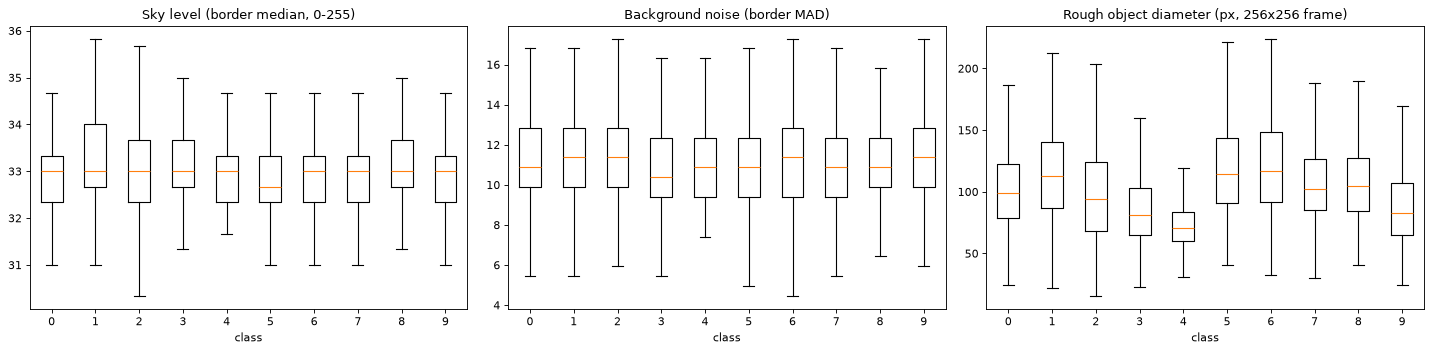

In [ ]:
qc = pd.DataFrame({
    "label": labels,
    "sky": st["sky"].astype(np.float64),
    "noise": st["noise"].astype(np.float64),
    "obj_diam_px": st["diam"].astype(np.float64),
    "redshift": redshift,
})
print(qc.groupby("label")[["sky", "noise", "obj_diam_px"]].median().round(2).to_string())
print("\nImages with no detected central object:", int((qc.obj_diam_px == 0).sum()))
print("Spearman(noise, redshift):", round(qc[["noise", "redshift"]].corr(method="spearman").iloc[0, 1], 3))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col, title in zip(
    axes,
    ["sky", "noise", "obj_diam_px"],
    ["Sky level (border median, 0-255)", "Background noise (border MAD)", "Rough object diameter (px, 256x256 frame)"],
):
    ax.boxplot([qc.loc[qc.label == c, col] for c in range(10)], showfliers=False)
    ax.set_xticklabels([str(c) for c in range(10)])
    ax.set_xlabel("class")
    ax.set_title(title)
fig.tight_layout()
savefig(fig, "qc_per_class.png")
plt.show()

## 8. Findings

- **Integrity:** The Galaxy10 DECaLS HDF5 file passes the published SHA256 integrity check, confirming the downloaded data is valid. The raw file is about 2.74 GB and uses gzip-compressed image storage, while metadata arrays remain uncompressed for efficient access.
- **Imbalance:** The dataset is strongly imbalanced. The largest class is Round Smooth (2645 images), while the smallest is Cigar Shaped Smooth (334 images), giving a 7.9:1 imbalance. Because of this, plain accuracy is not a reliable evaluation metric; macro-F1, balanced accuracy, or class-weighted loss should be preferred.
- **Memory considerations:** The full dataset is too large to keep in memory as float32 on a typical laptop, so the training pipeline should store images as uint8 and convert them to float32 only per batch. This keeps memory usage practical while preserving model compatibility.
- **Duplicates:** There are 60 exact duplicate image groups, involving 121 images. These duplicates should be removed or carefully separated during dataset splitting to prevent train/test leakage.
- **Metadata anomalies:** No NaN values were found in the metadata, and redshift/pxscale values are finite. The observed variation is consistent with the dataset specification, although class-level differences in object footprint and noise should still be checked.
- **Pixel QC:** Pixel intensities span the full 0–255 range, with 31 images showing more than 1% saturated pixels and 3 near-constant images. This suggests that some examples are significantly affected by image quality or background conditions.
- **Noise / sky by class:** The background level is roughly 33 across classes, and class-wise differences in noise and object size are visible. These differences may influence training dynamics and suggest that normalization and augmentation should be handled carefully.
- **Leakage risk:** Because closely related sky positions or repeated galaxy instances may appear in the dataset, the split should avoid placing near-duplicate samples across train and validation/test sets. This is essential for a fair and realistic estimate of generalization.